# 10 – Syntéza a porovnání bází ve 2. vrstvě (Silver): Fisher Discriminant Ratio, Silhouette & Mutual Information
Souhrnné vyhodnocení všech 9 matematických rodin nad zkopírovanými štítky z 1. vrstvy (`silver.method_runs`) a empirické ověření vhodnosti jednotlivých bází pro statickou zátěž, teplotní jevy a přechodové hrany.

,method_name,num_windows_processed,fdr_score,silhouette_score,davies_bouldin_score,mutual_info_mean,anova_f_mean,separability_by_phenomenon,compute_time_s
0,rqa_entropy,8470,0.4632,-0.1173,11.5548,0.2776,487.3925,"{'thermal_fdr': 0.4604, 'static_load_fdr': 0.0...",31.696
1,cwt,8470,0.2893,-0.0986,12.7722,0.2703,323.2033,"{'thermal_fdr': 0.3018, 'static_load_fdr': 0.0...",24.596
2,poincare,8470,0.2551,-0.1713,12.2254,0.3349,268.9101,"{'thermal_fdr': 0.249, 'static_load_fdr': 0.10...",7.234
3,fft_stft,8470,0.2286,-0.1037,7.7345,0.2960,255.4627,"{'thermal_fdr': 0.2288, 'static_load_fdr': 0.1...",7.302
4,cepstrum,8470,0.1797,-0.0793,10.9515,0.2277,186.0158,"{'thermal_fdr': 0.1764, 'static_load_fdr': 0.0...",1.674
5,time_stats,8470,0.1772,-0.0887,9.3248,0.3369,190.5574,"{'thermal_fdr': 0.1765, 'static_load_fdr': 0.0...",10.345
6,wvd,8470,0.1717,-0.1084,25.3791,0.2881,210.5771,"{'thermal_fdr': 0.1762, 'static_load_fdr': 0.0...",4.356
7,autoencoder,8470,0.0865,-0.0396,15.2022,0.2317,107.2741,"{'thermal_fdr': 0.0873, 'static_load_fdr': 0.0...",0.155
8,emd_hht,8470,0.0708,-0.2341,8.2649,0.2850,75.3298,"{'thermal_fdr': 0.0673, 'static_load_fdr': 0.1...",35.344


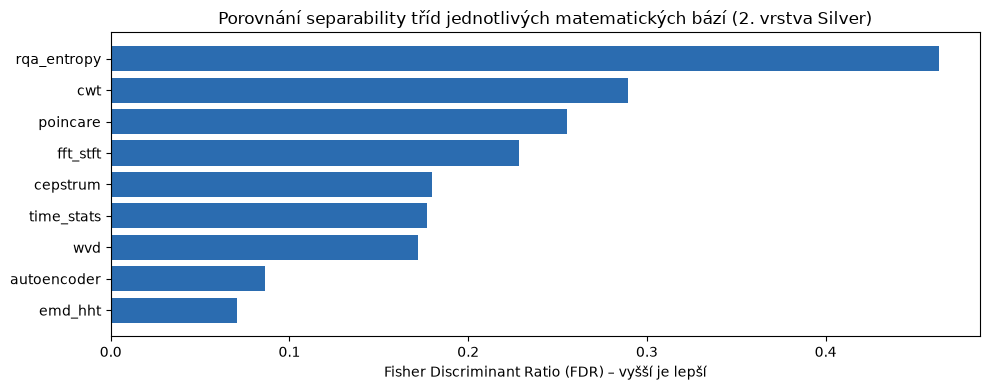

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from icaros.db.pg import fetch_all

runs = fetch_all('''
    SELECT method_name, num_windows_processed, fdr_score, silhouette_score,
           davies_bouldin_score, mutual_info_mean, anova_f_mean,
           separability_by_phenomenon, compute_time_s
    FROM silver.method_runs
    WHERE window_config_name = 'win128_stride32'
    ORDER BY fdr_score DESC
''')
df_runs = pd.DataFrame(runs)
display(df_runs)

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(df_runs['method_name'][::-1], df_runs['fdr_score'][::-1], color='#2b6cb0')
ax.set_xlabel('Fisher Discriminant Ratio (FDR) – vyšší je lepší')
ax.set_title('Porovnání separability tříd jednotlivých matematických bází (2. vrstva Silver)')
plt.tight_layout()
plt.show()